In [ ]:
import h5py
import numpy as np


caminho_arquivo = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\cohface\cohface\1\0\data.hdf5"

# Abrir e ler os datasets
with h5py.File(caminho_arquivo, 'r') as f:
    pulse = f['/pulse'][:]        # Carrega como array NumPy
    respiration = f['/respiration'][:]
    time = f['/time'][:]

# Exemplo de verificação
print("Pulse:", pulse.shape, pulse[:5])
print("Respiration:", respiration.shape, respiration[:5])
print("Time:", time.shape, time[:5])

Pulse: (15440,) [0.006 0.048 0.2   0.572 1.28 ]
Respiration: (15440,) [19. 19. 19. 19. 19.]
Time: (15440,) [0.00390625 0.0078125  0.01171875 0.015625   0.01953125]


Tamanho do pulse: (15440,)
Primeiros 10 valores de pulse: [6.0000e-03 4.8000e-02 2.0000e-01 5.7200e-01 1.2800e+00 2.4230e+00
 4.0690e+00 6.2430e+00 8.9370e+00 1.2104e+01]
Tamanho do time: (15440,)
Primeiros 10 valores de time: [0.00390625 0.0078125  0.01171875 0.015625   0.01953125 0.0234375
 0.02734375 0.03125    0.03515625 0.0390625 ]


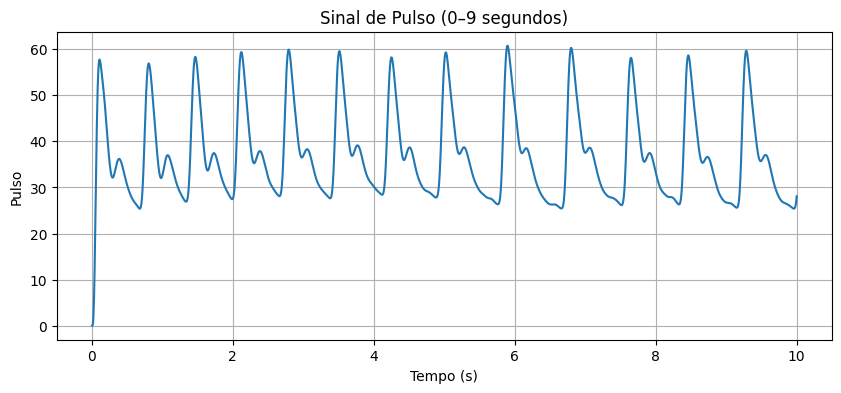

In [2]:
import h5py
import matplotlib.pyplot as plt

# Caminho para seu arquivo HDF5
hdf5_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\MATRIZ_CWT\data.hdf5"

# Abrir o arquivo HDF5 e acessar os dados
with h5py.File(hdf5_path, 'r') as f:
    pulse = f['/pulse'][:]
    time = f['/time'][:]

# Imprimir informações básicas
print(f"Tamanho do pulse: {pulse.shape}")
print(f"Primeiros 10 valores de pulse: {pulse[:10]}")
print(f"Tamanho do time: {time.shape}")
print(f"Primeiros 10 valores de time: {time[:10]}")

# Plotar os primeiros 9 segundos
mask = (time >= 0) & (time <= 10)
pulse_9s = pulse[mask]
time_9s = time[mask]

plt.figure(figsize=(10, 4))
plt.plot(time_9s, pulse_9s)
plt.title("Sinal de Pulso (0–9 segundos)")
plt.xlabel("Tempo (s)")
plt.ylabel("Pulso")
plt.grid(True)
plt.show()

In [ ]:
import torch
import numpy as np
import h5py
from Model_CNN import IPPGCNN
import torch.nn.functional as F
from scipy.signal import find_peaks

# Caminhos dos arquivos
npy_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\MATRIZ_CWT\data\data_cwt.npy"
hdf5_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\MATRIZ_CWT\data.hdf5"
# Carregar espectrograma (shape: 60x60)
spec = np.load(npy_path)
spec = np.expand_dims(spec, axis=0)  # (1, 60, 60)
spec = torch.tensor(spec, dtype=torch.float32)

# Carregar valor de pulso dos 9 primeiros segundos
with h5py.File(hdf5_path, "r") as f:
    pulse = f["pulse"][:]
    time = f["time"][:]

# Filtrar os primeiros 9 segundos
mask = time <= 9
pulse_segment = pulse[mask]
time_segment = time[mask]

peaks, _ = find_peaks(pulse_segment, distance=30)  # distância depende da amostragem
duracao = time_segment[-1] - time_segment[0]
bpm = (len(peaks) / duracao) * 60

print(f"Pulso real (média 0–9s): {bpm:.2f} bpm")


# Instanciar modelo
model = IPPGCNN()

# (Opcional) Carregar pesos treinados
try:
    model.load_state_dict(torch.load("ippg_cnn_model.pth"))
    print("Modelo carregado com sucesso.")
except FileNotFoundError:
    print("Modelo não encontrado, usando pesos aleatórios.")

model.eval()
# Garante que o espectrograma tem tamanho 60x60
spec = F.interpolate(spec.unsqueeze(0), size=(60, 60), mode='bilinear', align_corners=False).squeeze(0)
# Fazer previsão
with torch.no_grad():
    pred = model(spec.unsqueeze(0))  # (1, 1, 60, 60)
    predicted_pulse = pred.item()

print(f"Pulso estimado pela CNN: {predicted_pulse:.2f} bpm")


Número de picos detectados: 11
Estimativa de BPM: 10.07


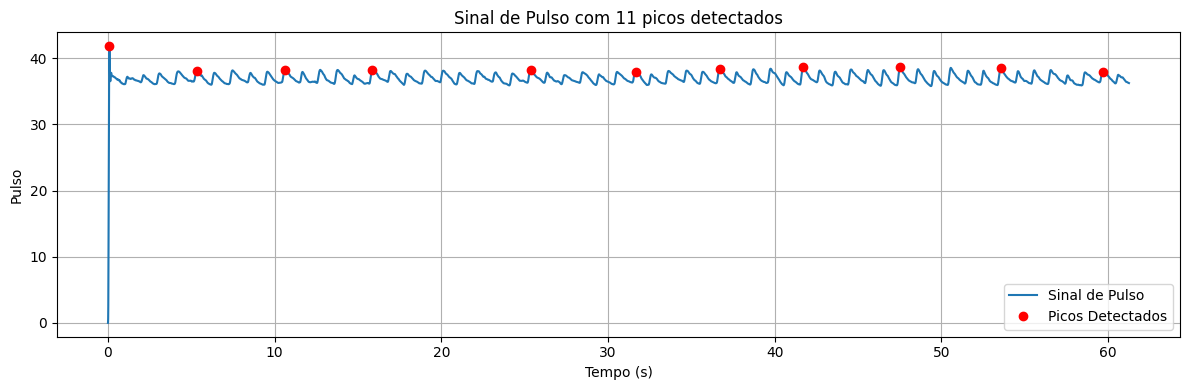

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# === Caminho para seu arquivo HDF5 ===
hdf5_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TESTE_COHFACE\34\0\data.hdf5"  # Substitua aqui

# === Leitura dos dados ===
with h5py.File(hdf5_path, 'r') as f:
    pulse = f['/pulse'][:]
    time = f['/time'][:]
    mask = (time >= 0) & (time <= 9)
    pulse_9s = pulse[mask]
    time_9s = time[mask]
# === Parâmetros de detecção de pico ===
fs = 1 / (time[1] - time[0])     # Taxa de amostragem, ex: 256 Hz
min_distance_sec = 5           # Tempo mínimo entre picos (em segundos)
distance_samples = int(min_distance_sec * fs)

# === Detecção dos picos ===
peaks, _ = find_peaks(pulse, distance=distance_samples, prominence=0.2)

# === Cálculo de BPM ===
if len(peaks) >= 2:
    rr_intervals = np.diff(time[peaks])
    bpm = 60 / np.mean(rr_intervals)
else:
    bpm = np.nan  # Não há picos suficientes para calcular BPM

# === Exibir resultado ===
print(f"Número de picos detectados: {len(peaks)}")
print(f"Estimativa de BPM: {bpm:.2f}")

# === Plot do sinal com os picos ===
plt.figure(figsize=(12, 4))
plt.plot(time, pulse, label='Sinal de Pulso')
plt.plot(time[peaks], pulse[peaks], 'ro', label='Picos Detectados')
plt.xlabel("Tempo (s)")
plt.ylabel("Pulso")
plt.title(f"Sinal de Pulso com {len(peaks)} picos detectados")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()



0: 480x640 1 Face, 15.3ms
Speed: 1.5ms preprocess, 15.3ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 12.6ms
Speed: 1.0ms preprocess, 12.6ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 13.2ms
Speed: 1.0ms preprocess, 13.2ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 10.1ms
Speed: 0.8ms preprocess, 10.1ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 10.5ms
Speed: 0.9ms preprocess, 10.5ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 10.4ms
Speed: 0.8ms preprocess, 10.4ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 11.3ms
Speed: 0.9ms preprocess, 11.3ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)

0: 480x640 1 Face, 10.8ms
Speed: 1.0ms preprocess, 10.8ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)

0: 480x

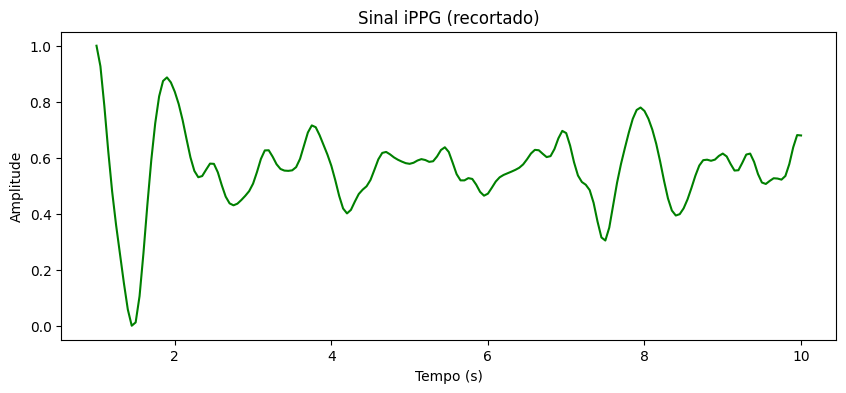

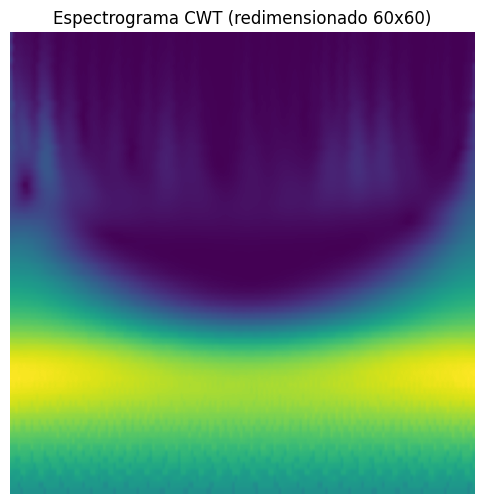

In [9]:
import cv2
import mediapipe as mp
import os
import matplotlib.pyplot as plt 
import numpy as np
from scipy.signal import butter, filtfilt
from scipy.signal import savgol_filter
import pywt
from ultralytics import YOLO
from scipy.ndimage import zoom

# ---------- Funções auxiliares ----------
def butter_bandpass(lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_bandpass_filter(data, lowcut, highcut, fs, order=4):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    return filtfilt(b, a, data)

def moving_average(signal, window_size):
    return np.convolve(signal, np.ones(window_size) / window_size, mode='valid')

def remove_baseline(signal, poly_order=2):
    x = np.arange(len(signal))
    coeffs = np.polyfit(x, signal, poly_order)  
    baseline = np.polyval(coeffs, x)     
    return signal - baseline

def normalized_signal(signal):
    sig= np.array(signal) 
    return (sig - np.min(sig)) / (np.max(sig) - np.min(sig))

# ---------- Inicialização ----------
model = YOLO("C:/Users/Douglas/Downloads/yolov8m_200e.pt")
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=False, max_num_faces=1, refine_landmarks=True)

# Caminho do vídeo
video_path = r"c:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\cohface\cohface\4\0\data.avi"
cap = cv2.VideoCapture(video_path) 

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# ROI e parâmetros
resize_dim = (115, 50)      
green_signal, R_channel, G_channel, B_channel = [], [], [], []

# ---------- Processamento de frames ----------
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    results = model.predict(frame, device='cuda')
    boxes = results[0].boxes.xyxy.cpu().numpy()

    if len(boxes) > 0:
        x1, y1, x2, y2 = boxes[0].astype(int)
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(frame_width, x2), min(frame_height, y2)

        face_roi = frame[y1:y2, x1:x2]
        frame_rgb_roi = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB)

        result = face_mesh.process(frame_rgb_roi)

        if result.multi_face_landmarks:
            roi = face_roi
            if roi.size > 0:
                resized_roi = cv2.resize(roi, resize_dim)
                R_channel.append(np.mean(resized_roi[:, :, 2]))
                G_channel.append(np.mean(resized_roi[:, :, 1]))
                B_channel.append(np.mean(resized_roi[:, :, 0]))
                green_signal.append(np.mean(resized_roi[:, :, 1]))

cap.release()

# ---------- Pós-processamento ----------
R_channel = np.array(R_channel)
G_channel = np.array(G_channel)
B_channel = np.array(B_channel)

X_POS = G_channel - 0.5 * (R_channel + B_channel)
Y_POS = 3 * G_channel - 2 * R_channel - B_channel
X_POS = (X_POS - np.mean(X_POS)) / np.std(X_POS)
Y_POS = (Y_POS - np.mean(Y_POS)) / np.std(Y_POS)
S_POS = X_POS + Y_POS

# Filtragem e normalização
lowcut, highcut, window_size, poly_order = 0.7, 4.0, 10, 2
filtered_signal = apply_bandpass_filter(S_POS, lowcut, highcut, fps)
smoothed_signal = moving_average(filtered_signal, window_size)
baseline_removed_signal = remove_baseline(smoothed_signal, poly_order)
IPPG = normalized_signal(baseline_removed_signal)

# Recorte
total_frames = 1200
duracao_total = 60      
fps = total_frames / duracao_total
frames = np.arange(0, len(IPPG))  
tempo = frames / fps
inicio_frame, fim_frame = int(1 * fps), int(10 * fps)
sinal_recortado = IPPG[inicio_frame:fim_frame + 1]
tempo_recortado = tempo[inicio_frame:fim_frame + 1]

# ---------- CWT ----------
widths = np.geomspace(1, 1024, num=75)
cwtmatr, freqs = pywt.cwt(
    sinal_recortado, widths, 'cgau1', sampling_period=np.diff(tempo_recortado).mean()
)
cwtmatr = np.abs(cwtmatr[:-1, :-1])

# ---------- Plot ----------
plt.figure(figsize=(10,4))
plt.plot(tempo_recortado, sinal_recortado, color="green")
plt.title("Sinal iPPG (recortado)")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.show()

plt.figure(figsize=(6,6))
plt.imshow(cwtmatr, cmap='viridis', aspect='auto')
plt.title("Espectrograma CWT (redimensionado 60x60)")
plt.axis("off")
plt.show()


In [1]:
import numpy as np

# Caminho do arquivo
npy_path = r"c:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\3\1\data\data_cwt.npy"

# Carregar o arquivo
data = np.load(npy_path)

# Mostrar informações
print("Tipo de dado:", type(data))
print("Formato (shape):", data.shape)
print("Número de dimensões:", data.ndim)
print("Tipo dos elementos:", data.dtype)

Tipo de dado: <class 'numpy.ndarray'>
Formato (shape): (74, 261)
Número de dimensões: 2
Tipo dos elementos: float64


In [12]:
import os
import numpy as np
import h5py
from scipy.signal import find_peaks

# Caminho base da COHFACE (ajuste se necessário)
base_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\cohface\cohface"

total_samples = 0
invalid_samples = 0
bpm_values = []

for person_id in range(1, 41):  # indivíduos 1 a 40
    person_path = os.path.join(base_path, str(person_id))

    if not os.path.exists(person_path):
        continue

    for session_name in os.listdir(person_path):
        session_path = os.path.join(person_path, session_name)
        hdf5_path = os.path.join(session_path, "data.hdf5")

        if not os.path.exists(hdf5_path):
            continue

        try:
            with h5py.File(hdf5_path, 'r') as f:
                pulse = f['/pulse'][:]
                time = f['/time'][:]

                # Considera os primeiros 9 segundos (igual ao código do dataset)
                mask = (time >= 0) & (time <= 9)
                pulse_segment = pulse[mask]
                time_segment = time[mask]

                if len(pulse_segment) < 2:
                    bpm = np.nan
                else:
                    # Picos do sinal de pulso
                    min_distance_sec = 0.6   
                    peaks, _ = find_peaks(pulse_segment, distance=distance_samples, prominence=0.5)
                    if len(peaks) < 2:
                        bpm = np.nan
                    else:
                        bpm = 60.0 / np.mean(np.diff(time_segment[peaks]))

                # Contabiliza
                total_samples += 1
                if np.isnan(bpm) or bpm <= 0 or bpm > 200:
                    invalid_samples += 1
                else:
                    bpm_values.append(bpm)

        except Exception as e:
            print(f"Erro ao processar {hdf5_path}: {e}")

# Resultados
valid_samples = total_samples - invalid_samples
mean_bpm = np.mean(bpm_values) if bpm_values else np.nan
std_bpm = np.std(bpm_values) if bpm_values else np.nan

print("\n===== Estatísticas do Dataset COHFACE =====")
print(f"Total de amostras: {total_samples}")
print(f"Amostras válidas: {valid_samples}")
print(f"Amostras inválidas (NaN ou fora do range): {invalid_samples}")
print(f"Percentual inválido: {100 * invalid_samples / total_samples:.2f}%")
print(f"Média dos BPM válidos: {mean_bpm:.2f}")
print(f"Desvio padrão dos BPM válidos: {std_bpm:.2f}")
print("============================================")



===== Estatísticas do Dataset COHFACE =====
Total de amostras: 160
Amostras válidas: 160
Amostras inválidas (NaN ou fora do range): 0
Percentual inválido: 0.00%
Média dos BPM válidos: 70.92
Desvio padrão dos BPM válidos: 10.86


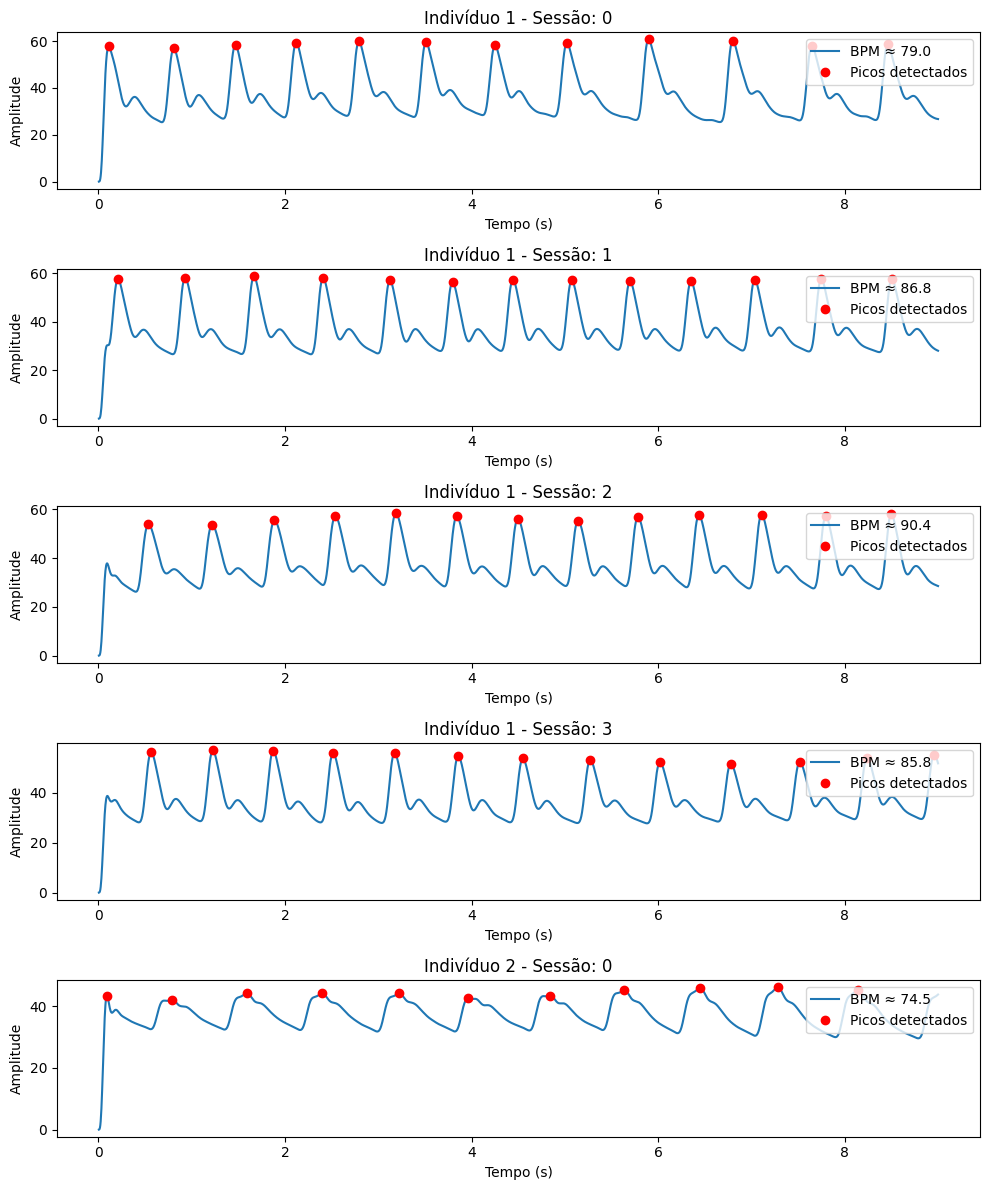

In [11]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Caminho base da COHFACE
base_path = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\cohface\cohface"

# Parâmetros
max_samples_to_plot = 5
plotted = 0

plt.figure(figsize=(10, 12))
plot_index = 1

for person_id in range(1, 41):
    person_path = os.path.join(base_path, str(person_id))
    if not os.path.exists(person_path):
        continue

    for session_name in os.listdir(person_path):
        session_path = os.path.join(person_path, session_name)
        hdf5_path = os.path.join(session_path, "data.hdf5")

        if not os.path.exists(hdf5_path):
            continue

        try:
            with h5py.File(hdf5_path, 'r') as f:
                pulse = f['/pulse'][:]
                time = f['/time'][:]

                # Recorte de 9 segundos
                mask = (time >= 0) & (time <= 9)
                pulse_segment = pulse[mask]
                time_segment = time[mask]

                if len(pulse_segment) < 2:
                    continue

                # Identificar picos
                min_distance_sec = 0.6   
                peaks, _ = find_peaks(pulse_segment, distance=distance_samples, prominence=0.5)

                # Calcular BPM
                if len(peaks) >= 2:
                    bpm = 60.0 / np.mean(np.diff(time_segment[peaks]))
                else:
                    continue

                # Plotar o sinal com os picos
                plt.subplot(max_samples_to_plot, 1, plot_index)
                plt.plot(time_segment, pulse_segment, label=f"BPM ≈ {bpm:.1f}")
                plt.plot(time_segment[peaks], pulse_segment[peaks], "ro", label="Picos detectados")
                plt.title(f"Indivíduo {person_id} - Sessão: {session_name}")
                plt.xlabel("Tempo (s)")
                plt.ylabel("Amplitude")
                plt.legend(loc="upper right")

                plotted += 1
                plot_index += 1
                if plotted >= max_samples_to_plot:
                    break

        except Exception as e:
            print(f"Erro em {hdf5_path}: {e}")

    if plotted >= max_samples_to_plot:
        break

plt.tight_layout()
plt.show()


In [3]:
from IPPG_Dataset import IPPGDataset  # se estiver em outro arquivo .py
import numpy as np
import h5py

# Caminho da pasta raiz dos dados
root_dir = r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE"

# Instancia o dataset (sem alterar a classe)
dataset = IPPGDataset(root_dir=root_dir)

# Cria lista para armazenar os BPMs calculados
bpm_values = []

# Percorre todos os samples e calcula o BPM novamente
for _, hdf5_path in dataset.samples:
    with h5py.File(hdf5_path, 'r') as f:
        pulse = f['/pulse'][:]
        time = f['/time'][:]
        mask = (time >= 0) & (time <= 9)
        pulse_9s = pulse[mask]
        time_9s = time[mask]
        bpm = dataset.calcular_bpm(pulse_9s, time_9s)
        bpm_values.append(bpm)

# Imprime os valores encontrados
print("\n=== Lista de BPMs calculados ===")
for i, bpm in enumerate(bpm_values):
    print(f"[{i}] BPM = {bpm:.2f}" if not np.isnan(bpm) else f"[{i}] BPM = NaN")

# Exibe resumo estatístico
valid_bpm = [b for b in bpm_values if not np.isnan(b)]
print(f"\nTotal de amostras: {len(bpm_values)}")
print(f"Válidas: {len(valid_bpm)} | Inválidas (NaN): {len(bpm_values) - len(valid_bpm)}")
print(f"Média: {np.mean(valid_bpm):.2f} | Desvio padrão: {np.std(valid_bpm):.2f}")

[INFO] Média BPM global: 72.24, Desvio padrão: 9.66

=== Lista de BPMs calculados ===
[0] BPM = 79.03
[1] BPM = 86.82
[2] BPM = 90.40
[3] BPM = 85.77
[4] BPM = 87.11
[5] BPM = 87.27
[6] BPM = 82.78
[7] BPM = 84.51
[8] BPM = 62.19
[9] BPM = 67.50
[10] BPM = 68.42
[11] BPM = 73.53
[12] BPM = 58.32
[13] BPM = 55.39
[14] BPM = 54.06
[15] BPM = 57.64
[16] BPM = 66.98
[17] BPM = 65.95
[18] BPM = 61.25
[19] BPM = 68.12
[20] BPM = 77.26
[21] BPM = 80.42
[22] BPM = 75.63
[23] BPM = 84.51
[24] BPM = 82.10
[25] BPM = 85.65
[26] BPM = 80.46
[27] BPM = 83.48
[28] BPM = 58.74
[29] BPM = 55.54
[30] BPM = 56.63
[31] BPM = 58.60
[32] BPM = 57.85
[33] BPM = 61.52
[34] BPM = 74.83
[35] BPM = 58.71
[36] BPM = 81.02
[37] BPM = 81.04
[38] BPM = 75.52
[39] BPM = 81.39
[40] BPM = 69.66
[41] BPM = 72.35
[42] BPM = 72.38
[43] BPM = 71.28
[44] BPM = 74.49
[45] BPM = 75.81
[46] BPM = 71.71
[47] BPM = 78.48
[48] BPM = 74.06
[49] BPM = 73.99
[50] BPM = 79.47
[51] BPM = 77.54
[52] BPM = 76.23
[53] BPM = 78.88
[54] B

In [12]:
import os
import glob
import numpy as np

def load_cwt(path):
    return np.load(path)

def compute_similarity(a, b):
    # Garantir mesmo tamanho
    fa = a.reshape(-1)
    fb = b.reshape(-1)

    min_len = min(len(fa), len(fb))
    fa = fa[:min_len]
    fb = fb[:min_len]

    # Métricas
    mse = np.mean((fa - fb) ** 2)
    corr = np.corrcoef(fa, fb)[0, 1]
    cos_sim = fa.dot(fb) / (np.linalg.norm(fa) * np.linalg.norm(fb) + 1e-12)

    return mse, corr, cos_sim


def percorrer_e_comparar(root_dir, referencia_idx=0):
    print("[INFO] Procurando arquivos data_cwt.npy...")

    cwt_paths = glob.glob(os.path.join(root_dir, "**", "data", "data_cwt.npy"), recursive=True)
    cwt_paths = sorted(cwt_paths)

    print(f"[INFO] Total encontrado: {len(cwt_paths)} arquivos CWT")

    if len(cwt_paths) < 2:
        raise ValueError("É necessário ter pelo menos 2 arquivos data_cwt.npy")

    # === Carregar arquivo de referência ===
    ref_path = cwt_paths[referencia_idx]
    print(f"\n[INFO] Arquivo de referência escolhido:\n   {ref_path}")

    ref_cwt = load_cwt(ref_path)

    # === Acumuladores ===
    mse_list = []
    corr_list = []
    cos_list = []

    # === Comparar todos com o arquivo de referência ===
    print("\n[INFO] Iniciando comparação...")
    for path in cwt_paths:
        if path == ref_path:
            continue

        cwt = load_cwt(path)
        mse, corr, cos = compute_similarity(ref_cwt, cwt)

        mse_list.append(mse)
        corr_list.append(corr)
        cos_list.append(cos)

        print(f"\nComparação:")
        print(f"Arquivo: {path}")
        print(f" - MSE: {mse:.6f}")
        print(f" - Corr: {corr:.6f}")
        print(f" - CosSim: {cos:.6f}")

    # === Resultados finais ===
    print("\n======================")
    print(" MÉDIA DE SIMILARIDADE")
    print("======================")
    print(f"MSE médio:       {np.mean(mse_list):.8f}")
    print(f"Correlação média:{np.mean(corr_list):.8f}")
    print(f"Cosseno médio:   {np.mean(cos_list):.8f}")

    return {
        "mse_medio": np.mean(mse_list),
        "corr_media": np.mean(corr_list),
        "cos_media": np.mean(cos_list),
        "total_arquivos": len(cwt_paths)
    }


resultados = percorrer_e_comparar(r"C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE")

print(resultados)

[INFO] Procurando arquivos data_cwt.npy...
[INFO] Total encontrado: 96 arquivos CWT

[INFO] Arquivo de referência escolhido:
   C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\10\0\data\data_cwt.npy

[INFO] Iniciando comparação...

Comparação:
Arquivo: C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\10\1\data\data_cwt.npy
 - MSE: 0.030402
 - Corr: 0.996111
 - CosSim: 0.997928

Comparação:
Arquivo: C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\10\2\data\data_cwt.npy
 - MSE: 0.015970
 - Corr: 0.996743
 - CosSim: 0.998090

Comparação:
Arquivo: C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\TREINAMENTO_COHFACE\10\3\data\data_cwt.npy
 - MSE: 0.026389
 - Corr: 0.994309
 - CosSim: 0.996909

Comparação:
Arquivo: C:\Users\Douglas\OneDrive - cefet-rj.br\Documentos\Material _ faculdade\Projeto IC\

In [ ]:
count = 0
input_M = input()
M = int(input_M)
input_N = input ()
N = int(input_N)
acumulador = int(input_M)
for acumulador in  range (M, N + 1, ):
    count = count + 1 
    acumulador = acumulador + M

print (count, acumulador)

0 8


In [ ]:
M = int(input("Digite M: "))
N = int(input("Digite N: "))

count = 0

# Começa em M e vai até N, pulando de M em M
for num in range(M, N+1, M):
    count += 1

print("Quantidade:", count)

Quantidade: 3
